# 01 · Exploratory data analysis
CDC Diabetes Health Indicators (BRFSS survey). Goal of this notebook: understand the data
before modelling — target balance, data quality, how the target relates to each feature, and
which features are strongly correlated (this matters later for PDP/permutation importance).

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.data import load, TARGET
sns.set_theme(style="whitegrid")
df = load()
print(df.shape)
df.head()

(253680, 22)


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


## 1. Data quality

In [2]:
print("missing values:", int(df.isna().sum().sum()))
print("duplicated rows:", int(df.duplicated().sum()), f"({df.duplicated().mean():.1%})")
df.describe().T[["min","mean","max"]].round(2)

missing values: 0
duplicated rows: 24206 (9.5%)


,min,mean,max
HighBP,0.0,0.43,1.0
HighChol,0.0,0.42,1.0
CholCheck,0.0,0.96,1.0
BMI,12.0,28.38,98.0
Smoker,0.0,0.44,1.0
Stroke,0.0,0.04,1.0
HeartDiseaseorAttack,0.0,0.09,1.0
PhysActivity,0.0,0.76,1.0
Fruits,0.0,0.63,1.0
Veggies,0.0,0.81,1.0


## 2. Target balance

In [3]:
print(df[TARGET].value_counts())
print(df[TARGET].value_counts(normalize=True).round(3))

Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64
Diabetes_binary
0    0.861
1    0.139
Name: proportion, dtype: float64


## 3. Prevalence of diabetes by feature
Binary features: diabetes rate when the feature is 0 vs 1. Ordinal features (`GenHlth`, `Age`, `Education`, `Income`): rate per level.

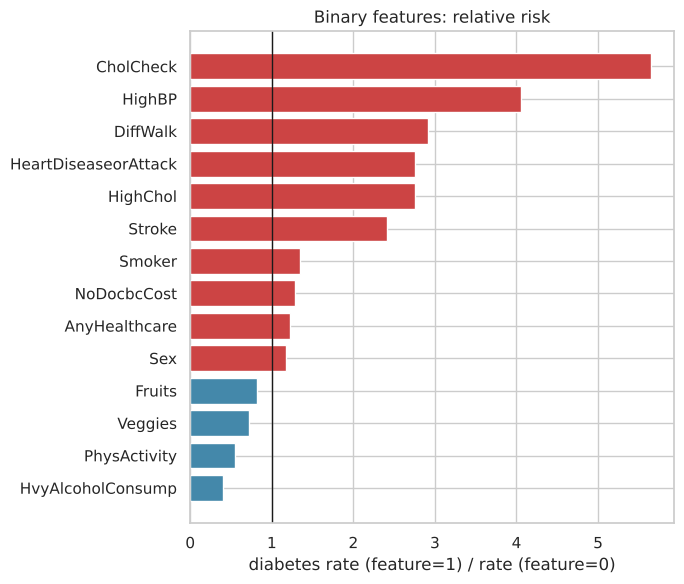

,feature,rate_if_0,rate_if_1,ratio
9,HvyAlcoholConsump,0.144,0.058,0.405
6,PhysActivity,0.211,0.116,0.549
8,Veggies,0.180,0.130,0.722
7,Fruits,0.158,0.129,0.814
13,Sex,0.130,0.152,1.169
10,AnyHealthcare,0.115,0.141,1.228
11,NoDocbcCost,0.136,0.175,1.288
3,Smoker,0.121,0.163,1.352
4,Stroke,0.132,0.318,2.409
1,HighChol,0.080,0.220,2.758


In [4]:
binary = [c for c in df.columns if c != TARGET and df[c].nunique() == 2]
rows = [(c, df.loc[df[c]==0, TARGET].mean(), df.loc[df[c]==1, TARGET].mean()) for c in binary]
b = pd.DataFrame(rows, columns=["feature","rate_if_0","rate_if_1"]).assign(ratio=lambda d: d.rate_if_1/d.rate_if_0).sort_values("ratio")
fig, ax = plt.subplots(figsize=(7,6))
ax.barh(b.feature, b.ratio, color=["#c44" if r>1 else "#48a" for r in b.ratio])
ax.axvline(1, color="k", lw=1); ax.set_xlabel("diabetes rate (feature=1) / rate (feature=0)")
ax.set_title("Binary features: relative risk")
plt.tight_layout(); plt.savefig("../figures/eda_binary_risk.png", dpi=150); plt.show()
b.round(3)

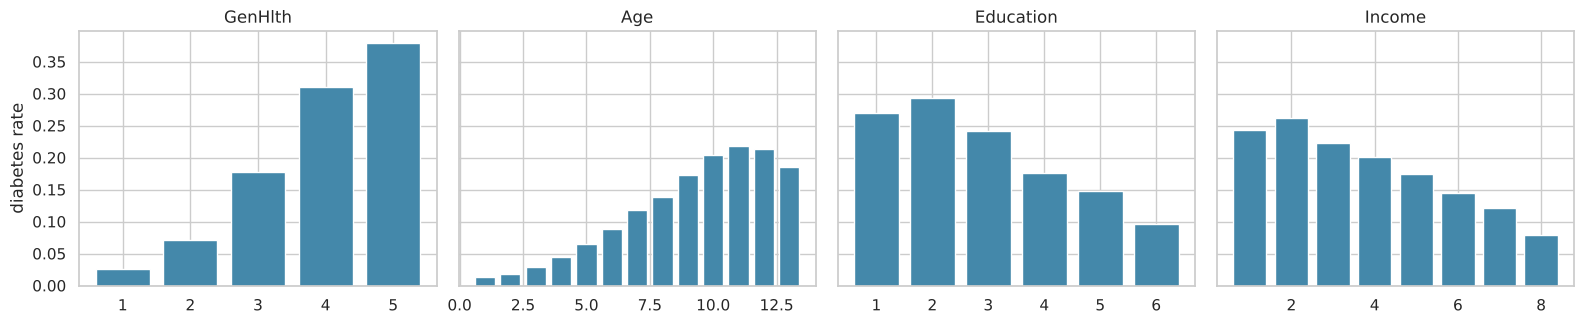

In [5]:
ordinal = ["GenHlth","Age","Education","Income"]
fig, axes = plt.subplots(1,4, figsize=(16,3.4), sharey=True)
for ax, c in zip(axes, ordinal):
    g = df.groupby(c)[TARGET].mean(); ax.bar(g.index, g.values, color="#48a"); ax.set_title(c)
axes[0].set_ylabel("diabetes rate")
plt.tight_layout(); plt.savefig("../figures/eda_ordinal_risk.png", dpi=150); plt.show()

## 4. BMI, MentHlth, PhysHlth (numeric)

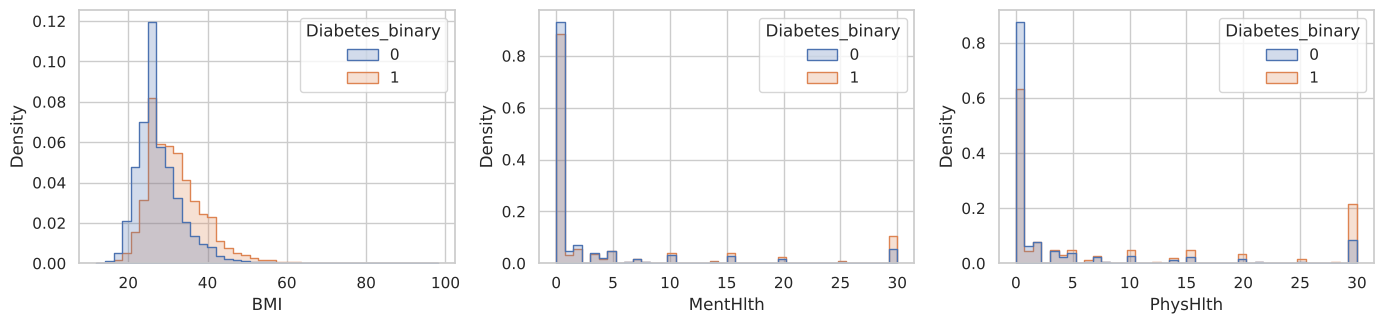

count    253680.0
mean         28.4
std           6.6
min          12.0
25%          24.0
50%          27.0
75%          31.0
max          98.0
Name: BMI, dtype: float64
BMI>50: 2175  BMI<15: 68


In [6]:
fig, axes = plt.subplots(1,3, figsize=(14,3.4))
for ax, c in zip(axes, ["BMI","MentHlth","PhysHlth"]):
    sns.histplot(data=df, x=c, hue=TARGET, stat="density", common_norm=False, bins=40, ax=ax, element="step")
plt.tight_layout(); plt.savefig("../figures/eda_numeric.png", dpi=150); plt.show()
print(df.BMI.describe().round(1)); print("BMI>50:", int((df.BMI>50).sum()), " BMI<15:", int((df.BMI<15).sum()))

## 5. Correlations
Correlation with the target (what a linear baseline can use) and between features
(strong pairs will split importance between them in permutation importance / SHAP).

Income                 -0.164
Education              -0.124
PhysActivity           -0.118
HvyAlcoholConsump      -0.057
Veggies                -0.057
Fruits                 -0.041
AnyHealthcare           0.016
Sex                     0.031
NoDocbcCost             0.031
Smoker                  0.061
CholCheck               0.065
MentHlth                0.069
Stroke                  0.106
PhysHlth                0.171
HeartDiseaseorAttack    0.177
Age                     0.177
HighChol                0.200
BMI                     0.217
DiffWalk                0.218
HighBP                  0.263
GenHlth                 0.294


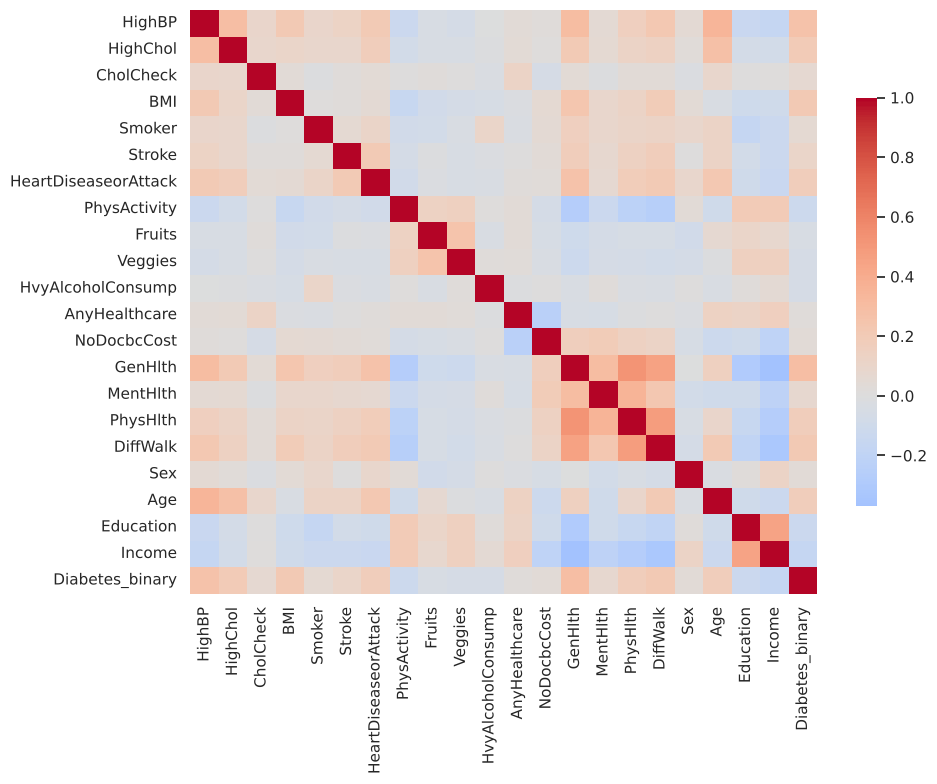

GenHlth    PhysHlth    0.524
PhysHlth   DiffWalk    0.478
GenHlth    DiffWalk    0.457
Education  Income      0.449
GenHlth    Income     -0.370
MentHlth   PhysHlth    0.354
HighBP     Age         0.344
DiffWalk   Income     -0.320
GenHlth    MentHlth    0.302
HighBP     GenHlth     0.301
dtype: float64

In [7]:
corr = df.corr(numeric_only=True)
t = corr[TARGET].drop(TARGET).sort_values()
print(t.round(3).to_string())
fig, ax = plt.subplots(figsize=(10,8))
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax, cbar_kws={"shrink":.7})
plt.tight_layout(); plt.savefig("../figures/eda_corr.png", dpi=150); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
pairs = pairs.drop(labels=[i for i in pairs.index if TARGET in i])
pairs[pairs.abs()>0.3].sort_values(key=abs, ascending=False).round(3)